# Parameter identification with data fitting
After conducting the experiment, we compare the recorded data with the calculated behavior of the mathematical model of the DC motor.

| column | meaning | unit |
|---|---|---|
| 0 | phase | |
| 1 | motor power setpoint | % |
| 2 | left wheel encoder (E4) | deg |
| 3 | right wheel encoder (E3) | deg |
| 4 | time since start of this power level | ms |
| 5 | battery voltage | V |

Because the battery voltage is logged, we can use the **actual voltage** applied to the motor, $U = \frac{power}{100}\,U_{bat}$, instead of a guessed constant.

In [13]:
try:
    from google.colab import files    # file work module
    uploaded = files.upload()         # upload file context window
except ImportError:
    pass

Saving steps_data_load.txt to steps_data_load (1).txt
Saving steps_data_2.txt to steps_data_2 (1).txt
Saving steps_data.txt to steps_data (1).txt
Saving signal_data.txt to signal_data (1).txt


Using the *loadtxt* function from the *numpy* module we read all six columns. The file holds many experiments one after another, so we split it into separate runs wherever the power setpoint changes, and convert the readings to SI units.

In [14]:
import numpy as np                  # array work module
import matplotlib.pyplot as plt     # data visualization
from scipy import optimize          # data fitting
from scipy.integrate import odeint  # ordinary differential equation solver

def load_runs(path):
    data = np.loadtxt(path)                                          # columns: phase, power, encL, encR, time_ms, battery
    phase_all, power_all, encL_all, encR_all, time_all, bat_all = data.T
    runs = []
    for p in np.unique(power_all):
        m = (power_all == p) & (phase_all == 1)                      # power-on lines of this level
        if not m.any():                                              # no power-on lines (power 0 in the floor run)
            continue
        runs.append({
            'power': p,                                              # setpoint, %
            'time':  time_all[m] / 1000,                             # SI conversion, s
            'L':     np.deg2rad(encL_all[m]),                        # SI conversion, rad
            'R':     np.deg2rad(encR_all[m]),                        # SI conversion, rad
            'U':     p / 100 * bat_all[m].mean(),                    # applied voltage, V
        })
    return runs, bat_all

FILES = {'run1':  'steps_data.txt',                                  # wheels lifted, run 1
         'run2':  'steps_data_2.txt',                                # wheels lifted, run 2 (repeatability)
         'floor': 'steps_data_load.txt'}                             # on the floor, ±50 % only (load)
all_runs, all_bat = {}, {}
for name, path in FILES.items():
    all_runs[name], all_bat[name] = load_runs(path)
    r = all_runs[name]
    print(f'{name}: {len(r)} runs, power {r[0]["power"]:.0f} .. {r[-1]["power"]:.0f} %, '
          f'battery {all_bat[name].min():.2f} .. {all_bat[name].max():.2f} V')

runs, bat_all = all_runs['run1'], all_bat['run1']                    # the cells below analyse run 1

run1: 21 runs, power -100 .. 100 %, battery 11.64 .. 11.67 V
run2: 21 runs, power -100 .. 100 %, battery 11.29 .. 11.33 V
floor: 2 runs, power -50 .. 50 %, battery 11.29 .. 11.30 V


Next, we define the motor rotation angle function to find optimal values of the steady-state speed $\omega_{ss}$ and $T_m$:
$$\theta(t) = \omega_{ss}\left(t - T_m + T_m e^{-t/T_m}\right), \qquad \omega_{ss} = \frac{U}{k_e}$$
Having real measurements of rotation angle versus time, we use *optimize.curve_fit*. The initial guess for the speed is taken from the data itself, so it works for any power level and direction.

## Derivation of $\theta(t)$

**From the motor equations to the first-order model.**

Electrical: $L\dfrac{di}{dt} + Ri + k_e\omega = U$

Mechanical: $J\dfrac{d\omega}{dt} = k_m i$

We assume $L$ is negligible, so

$$
0 + Ri + k_e\omega = U
\quad\Rightarrow\quad
i = \frac{U - k_e\omega}{R}
$$

Substituting into the mechanical equation:

$$
J\frac{d\omega}{dt} = \frac{k_m(U - k_e\omega)}{R}
\quad\Rightarrow\quad
JR\frac{d\omega}{dt} = k_mU - k_mk_e\omega
$$

$$
\frac{JR}{k_mk_e}\frac{d\omega}{dt} + \omega
= \frac{U}{k_e}
$$

so $T_m = \dfrac{JR}{k_mk_e}$ and
$\omega_{ss} = \dfrac{U}{k_e}$:

$$
T_m\frac{d\omega}{dt} + \omega = \omega_{ss},
\qquad
\omega(0) = 0
$$

**Solving for $\omega(t)$.** Dividing by $T_m$:

$$
\frac{d\omega}{dt} + \frac{\omega}{T_m}
= \frac{\omega_{ss}}{T_m},
\qquad
\mu = e^{\int \frac{1}{T_m}\,dt} = e^{t/T_m}
$$

Multiplying by $\mu$:

$$
\frac{d\omega}{dt}\,e^{t/T_m}
+ \frac{\omega}{T_m}\,e^{t/T_m}
= \frac{d}{dt}\left(\omega e^{t/T_m}\right)
= \frac{\omega_{ss}}{T_m}\,e^{t/T_m}
$$

$$
\int \frac{d}{dt}\left(\omega e^{t/T_m}\right)dt
= \int \frac{\omega_{ss}}{T_m}\,e^{t/T_m}\,dt
$$

$$
\omega e^{t/T_m} = \omega_{ss}e^{t/T_m} + C
\quad\Rightarrow\quad
\omega = \omega_{ss} + Ce^{-t/T_m}
$$

$$
\omega(0) = \omega_{ss} + C = 0
\;\Rightarrow\;
C = -\omega_{ss}
$$

$$
\omega(t) = \omega_{ss}\left(1 - e^{-t/T_m}\right)
$$

**Solving for $\theta(t)$.**
$\dfrac{d\theta}{dt} = \omega$, $\theta(0) = 0$:

$$
\theta(t) = \int \omega\,dt
= \omega_{ss}\int\left(1 - e^{-t/T_m}\right)dt
$$

$$
\theta(t) = \omega_{ss}\left(t + T_me^{-t/T_m}\right) + D
$$

$$
\theta(0) = \omega_{ss}T_m + D = 0
\;\Rightarrow\;
D = -T_m\omega_{ss}
$$

$$
\theta(t) = \omega_{ss}\left(t + T_me^{-t/T_m} - T_m\right)
= \omega_{ss}\left(t + T_m\left(e^{-t/T_m} - 1\right)\right)
$$

The line doesn't pass through the origin, but has a positive intercept, so it only describes the fitted range ($|PWM|\ge 50\%$). $k_e$ is the slope; the simulation uses the full line, $U/k_e + b$, so that it matches measured speeds.

**Model assumptions**

| # | Assumption | Holds? | Data note |
|---|---|---|---|
| 1 | Inductance $L$ is negligible | Consistent | $L$ was not measured, but step simulation at +100 % ends within −5.3 % (L) and −3.6 % (R) of the measured angle. |
| 2 | Friction is linear (viscous) | No, at low PWM | Below 10 % PWM the wheel does not move: static friction causes a dead zone. |
| 3 | The load is constant | Within a run | Valid for unloaded wheels. On the floor at ±50 %, $\omega_{ss}$ drops by 15–26 % and $T_m$ rises to 0.36–0.48 s. |
| 4 | The battery voltage is constant | Within a run | Run 1 drops by 0.3 %. Handled by computing $U$ from logged voltage. |
| 5 | $T_m$ and $\omega_{ss}$ are constant | Within a level | $T_m$ varies across levels (e.g., R from 0.075 s to 0.26 s); mean $T_m$ is an approximation. |
| 6 | The wheel is at rest and encoder is 0 when a level starts | Yes | Every level ends at rest and encoders are reset. |

In [15]:
def model(t, speed, T_m):
    return speed * t - speed * T_m + speed * T_m * np.exp(-t / T_m)  # definition of angle equation

def fit_run(t, ang):
    p0 = [ang[-1] / t[-1], 0.2]                                      # initial guess from data
    popt, pcov = optimize.curve_fit(model, t, ang, p0=p0,
                                 bounds=([-np.inf, 1e-3], [np.inf, 5]))  # T_m must stay positive
    err = np.sqrt(np.diag(pcov))                                     # standard errors
    return popt, err

## Results for the report
Every run is fitted for both wheels (power-on lines only); standard errors come from `pcov`.

- **$k_e$**: from the slope $s$ of a line $\omega_{ss} = s \cdot PWM + b$ over $|PWM| \ge 50\,\%$, per wheel and direction: $k_e = U_{bat}/(100\,s)$.
- **$T_m$**: mean over the same runs $\pm$ standard deviation across PWM levels.
- **Dead zone**: below 10 % PWM in both directions (step series), $\le 7\,\%$ forward (chirp).

In [19]:
import os
import numpy as np

os.makedirs('report_figs', exist_ok=True)

pct = np.array([r['power'] for r in runs])                         # PWM of every run, %
U = np.array([r['U'] for r in runs])                               # voltage of every run, V

w_ss, T_m_run, w_err, T_m_err = {}, {}, {}, {}
for wh in ('L', 'R'):
    w_ss[wh] = np.full(len(runs), np.nan)                            # steady-state speed, rad/s
    T_m_run[wh] = np.full(len(runs), np.nan)                         # time constant, s
    w_err[wh] = np.full(len(runs), np.nan)                           # standard error of w_ss
    T_m_err[wh] = np.full(len(runs), np.nan)                         # standard error of T_m
    for i, r in enumerate(runs):
        if abs(r[wh][-1]) >= 1:                                      # wheel moved
            (w_ss[wh][i], T_m_run[wh][i]), (w_err[wh][i], T_m_err[wh][i]) = fit_run(r['time'], r[wh])

lin = np.abs(pct) >= 50                                              # linear part
u_bat = bat_all.mean()                                               # battery voltage, V
params = {}

for wh in ('L', 'R'):
    for name, side in (('fwd', pct > 0), ('rev', pct < 0)):
        moved = side & ~np.isnan(w_ss[wh])
        f = moved & lin
        if f.sum() > 1:
            slope, b = np.polyfit(pct[f], w_ss[wh][f], 1)
        else:
            slope, b = 1.0, 0.0  # fallback if linear points are sparse

        k_e_val = u_bat / (100 * slope) if slope != 0 else np.nan
        params[wh, name] = {'dz':      np.abs(pct[moved]).min() if moved.any() else 0,
                            'slope':   slope,
                            'b':       b,
                            'k_e':     k_e_val,
                            'T_m':     np.nanmean(T_m_run[wh][f]) if f.any() else np.nan,
                            'T_m_std': np.nanstd(T_m_run[wh][f], ddof=1) if f.any() else 0.0}

rows = ['| Motor | Direction | Dead zone, % PWM | Slope, rad/s per % | b, rad/s | k_e, V·s/rad | T_m, s | U_battery, V |',
        '|---|---|---:|---:|---:|---:|---:|---:|']
for (wh, name), p in params.items():
    rows.append(f'| {wh} | {name} | < {p["dz"]:.0f} | {p["slope"]:.4f} | {p["b"]:+.2f} | {p["k_e"]:.3f} '
                f'| {p["T_m"]:.3f} ± {p["T_m_std"]:.3f} | {u_bat:.2f} |')

with open('report_figs/motor_table.md', 'w') as f:
    f.write('\n'.join(rows) + '\n')
print('\n'.join(rows))

def cell(x, digits):
    return '–' if np.isnan(x) else f'{x:.{digits}f}'

with open('report_figs/table.md', 'w') as f:
    f.write('| PWM, % | U, V | L: ω_ss, rad/s | L: T_m, s | R: ω_ss, rad/s | R: T_m, s |\n')
    f.write('|---:|---:|---:|---:|---:|---:|\n')
    for i in range(len(runs)):
        f.write(f'| {pct[i]:.0f} | {U[i]:.2f} | {cell(w_ss["L"][i], 2)} ± {cell(w_err["L"][i], 2)} | {cell(T_m_run["L"][i], 3)} ± {cell(T_m_err["L"][i], 3)}'
                f' | {cell(w_ss["R"][i], 2)} ± {cell(w_err["R"][i], 2)} | {cell(T_m_run["R"][i], 3)} ± {cell(T_m_err["R"][i], 3)} |\n')

print('Tables saved to report_figs/')

| Motor | Direction | Dead zone, % PWM | Slope, rad/s per % | b, rad/s | k_e, V·s/rad | T_m, s | U_battery, V |
|---|---|---:|---:|---:|---:|---:|---:|
| L | fwd | < 10 | 0.1196 | +3.36 | 0.974 | 0.188 ± 0.061 | 11.65 |
| L | rev | < 10 | 0.1044 | -3.86 | 1.115 | 0.197 ± 0.074 | 11.65 |
| R | fwd | < 10 | 0.1025 | +5.30 | 1.136 | 0.143 ± 0.050 | 11.65 |
| R | rev | < 10 | 0.0965 | -5.54 | 1.207 | 0.152 ± 0.064 | 11.65 |
Tables saved to report_figs/


$T_m$ against the applied voltage for every run, both wheels. $T_m$ is not constant, so as for $k_e$ we approximate it with a least-squares line, $T_m = a + b\,U$, separately for forward and reverse.

L fwd: T_m = -0.029 * U + 0.439 (s, U in V)
L rev: T_m = 0.028 * U + 0.439 (s, U in V)
R fwd: T_m = -0.034 * U + 0.450 (s, U in V)
R rev: T_m = 0.035 * U + 0.460 (s, U in V)


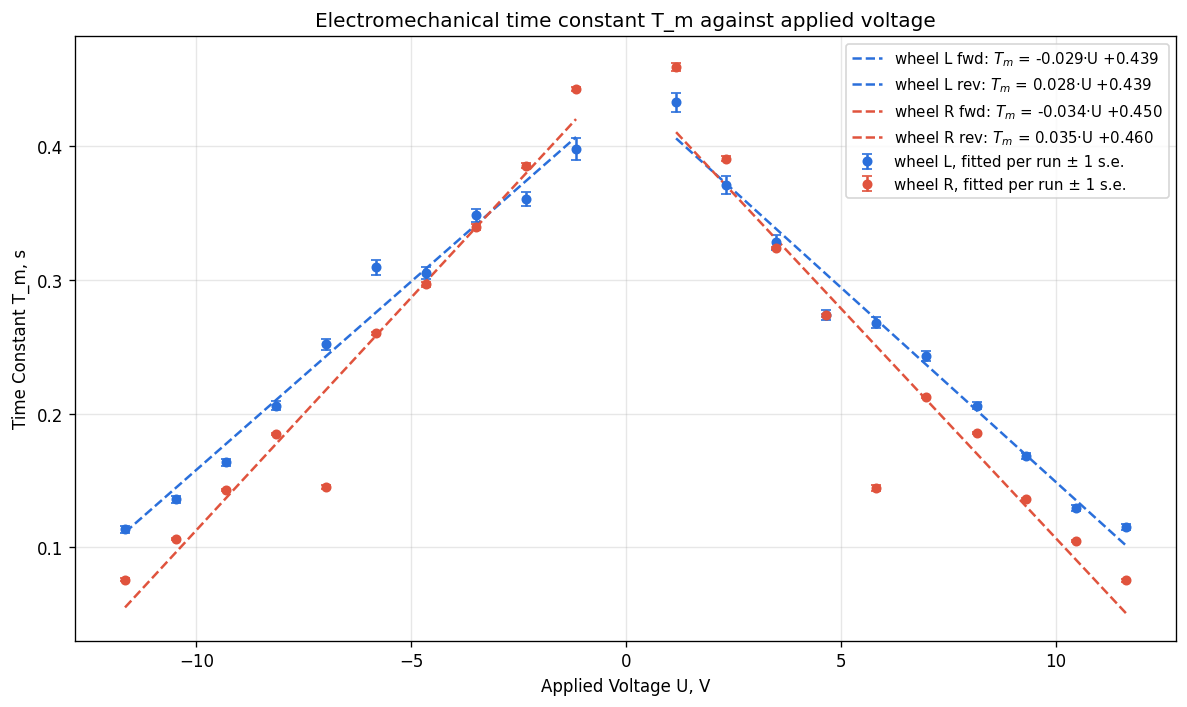

In [20]:
colors = {'L': '#2a6fdb', 'R': '#e0533d'}

plt.figure(figsize=(10, 6), dpi=120)
for wh in ('L', 'R'):
    plt.errorbar(U, T_m_run[wh], yerr=T_m_err[wh], fmt='o', color=colors[wh], ms=5,
                 capsize=3, label=f'wheel {wh}, fitted per run ± 1 s.e.')
    for side, name in ((U > 0, 'fwd'), (U < 0, 'rev')):
        m = side & ~np.isnan(T_m_run[wh])
        if m.sum() > 2:
            a, b = np.polyfit(U[m], T_m_run[wh][m], 1)
            U_line = np.linspace(U[m].min(), U[m].max(), 50)
            plt.plot(U_line, a * U_line + b, '--', color=colors[wh],
                     label=f'wheel {wh} {name}: $T_m$ = {a:.3f}·U {b:+.3f}')
            print(f'{wh} {name}: T_m = {a:.3f} * U + {b:.3f} (s, U in V)')

plt.xlabel('Applied Voltage U, V'); plt.ylabel('Time Constant T_m, s')
plt.title('Electromechanical time constant T_m against applied voltage')
plt.grid(alpha=0.3); plt.legend(fontsize=9)
plt.tight_layout(); plt.savefig('report_figs/T_m.png')
plt.show()

wheel L fwd: slope=0.1196, intercept=3.3617, k_e=0.9740 V*s/rad
wheel L rev: slope=0.1044, intercept=-3.8591, k_e=1.1152 V*s/rad
wheel R fwd: slope=0.1025, intercept=5.2990, k_e=1.1365 V*s/rad
wheel R rev: slope=0.0965, intercept=-5.5387, k_e=1.2072 V*s/rad


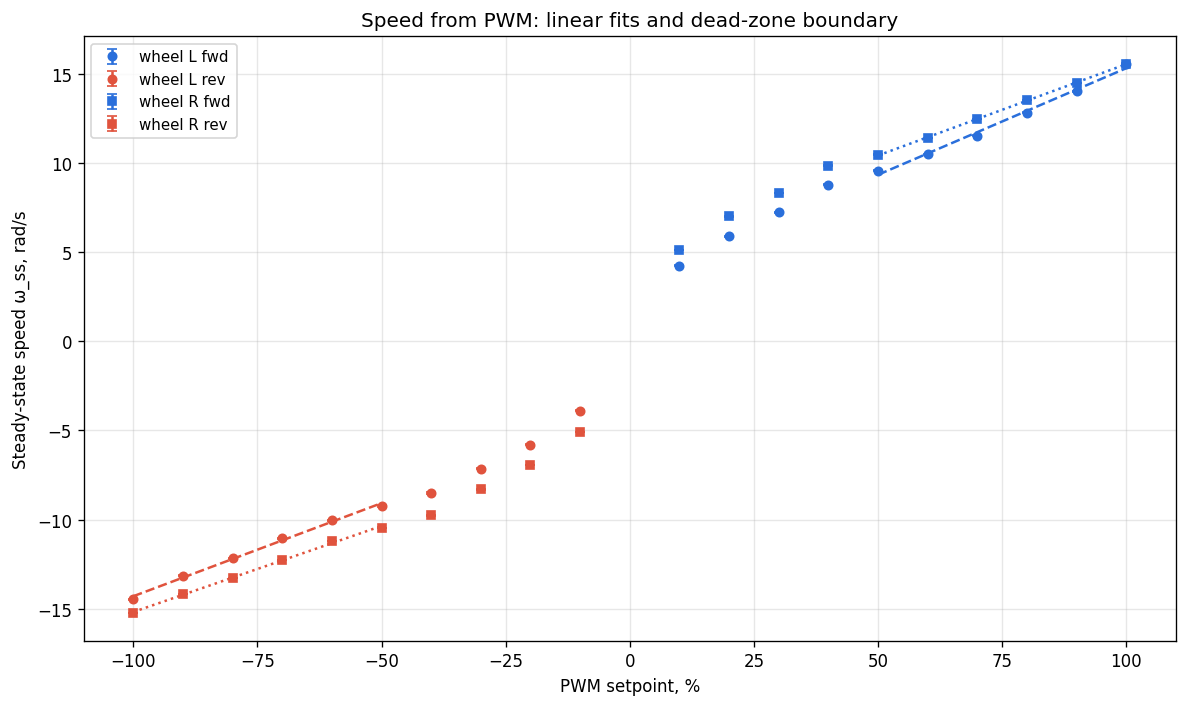

In [21]:
markers = {'L': 'o', 'R': 's'}
styles = {'L': '--', 'R': ':'}
dir_colors = {'fwd': '#2a6fdb', 'rev': '#e0533d'}

plt.figure(figsize=(10, 6), dpi=120)
for wh in ('L', 'R'):
    for side, name in ((pct > 0, 'fwd'), (pct < 0, 'rev')):
        m = side & ~np.isnan(w_ss[wh])
        plt.errorbar(pct[m], w_ss[wh][m], yerr=w_err[wh][m], fmt=markers[wh], color=dir_colors[name],
                     ms=5, capsize=3, label=f'wheel {wh} {name}')
        f = m & lin
        if f.sum() > 1:
            slope, icpt = np.polyfit(pct[f], w_ss[wh][f], 1)
            x_line = np.linspace(pct[f].min(), pct[f].max(), 50)
            plt.plot(x_line, slope * x_line + icpt, linestyle=styles[wh], color=dir_colors[name], lw=1.5)
            k_e_calc = u_bat / (100 * slope)
            print(f'wheel {wh} {name}: slope={slope:.4f}, intercept={icpt:.4f}, k_e={k_e_calc:.4f} V*s/rad')

plt.xlabel('PWM setpoint, %'); plt.ylabel('Steady-state speed ω_ss, rad/s')
plt.title('Speed from PWM: linear fits and dead-zone boundary')
plt.grid(alpha=0.3); plt.legend(fontsize=9)
plt.tight_layout(); plt.savefig('report_figs/speed_pwm.png')
plt.show()

Step response for the report: both wheels at full power, simulated with `odeint` using each wheel's identified $k_e$ and $T_m$ from above.

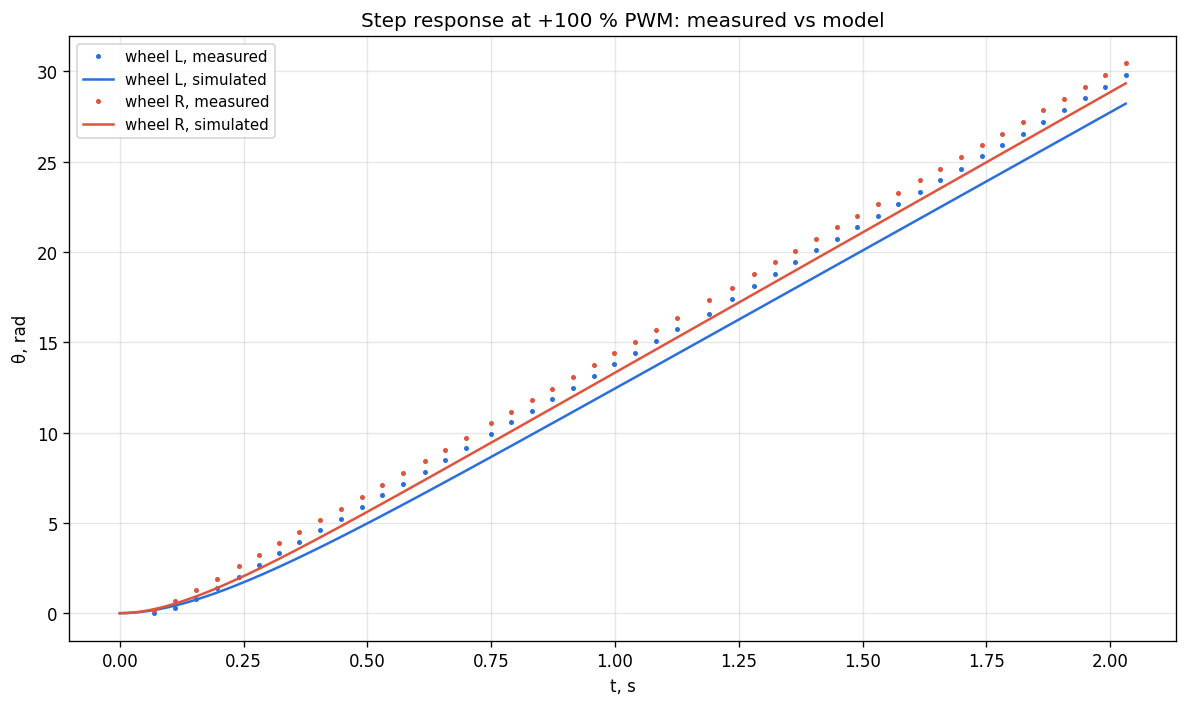

In [22]:
def motor_model(state, t, u, T_m, k_e, b):
    speed, angle = state
    w_target = u / k_e + b
    return [(w_target - speed) / T_m, speed]

run = next(r for r in runs if r['power'] == 100)
t_sim = np.linspace(0, run['time'][-1], 300)

plt.figure(figsize=(10, 6), dpi=120)
for wh in ('L', 'R'):
    p = params[wh, 'fwd']
    y_sim = odeint(motor_model, [0, 0], t_sim, args=(run['U'], p['T_m'], p['k_e'], p['b']))
    plt.plot(run['time'], run[wh], '.', color=colors[wh], ms=4, label=f'wheel {wh}, measured')
    plt.plot(t_sim, y_sim[:, 1], '-', color=colors[wh], lw=1.5, label=f'wheel {wh}, simulated')

plt.xlabel('t, s'); plt.ylabel('θ, rad')
plt.title('Step response at +100 % PWM: measured vs model')
plt.grid(alpha=0.3); plt.legend(fontsize=9)
plt.tight_layout(); plt.savefig('report_figs/step_resp.png')
plt.show()

How much the wheels differ at the same command, and what that does to a differential-drive robot (wheel radius and track width from the Week 4 odometry code). Also: how far the fitted line is off at low PWM.

wheel L, without dead zone: RMSE 2.13 rad, fit 18.1 %
wheel L, with dead zone: RMSE 1.05 rad, fit 59.6 %
wheel R, without dead zone: RMSE 6.97 rad, fit -127.3 %
wheel R, with dead zone: RMSE 3.29 rad, fit -7.3 %


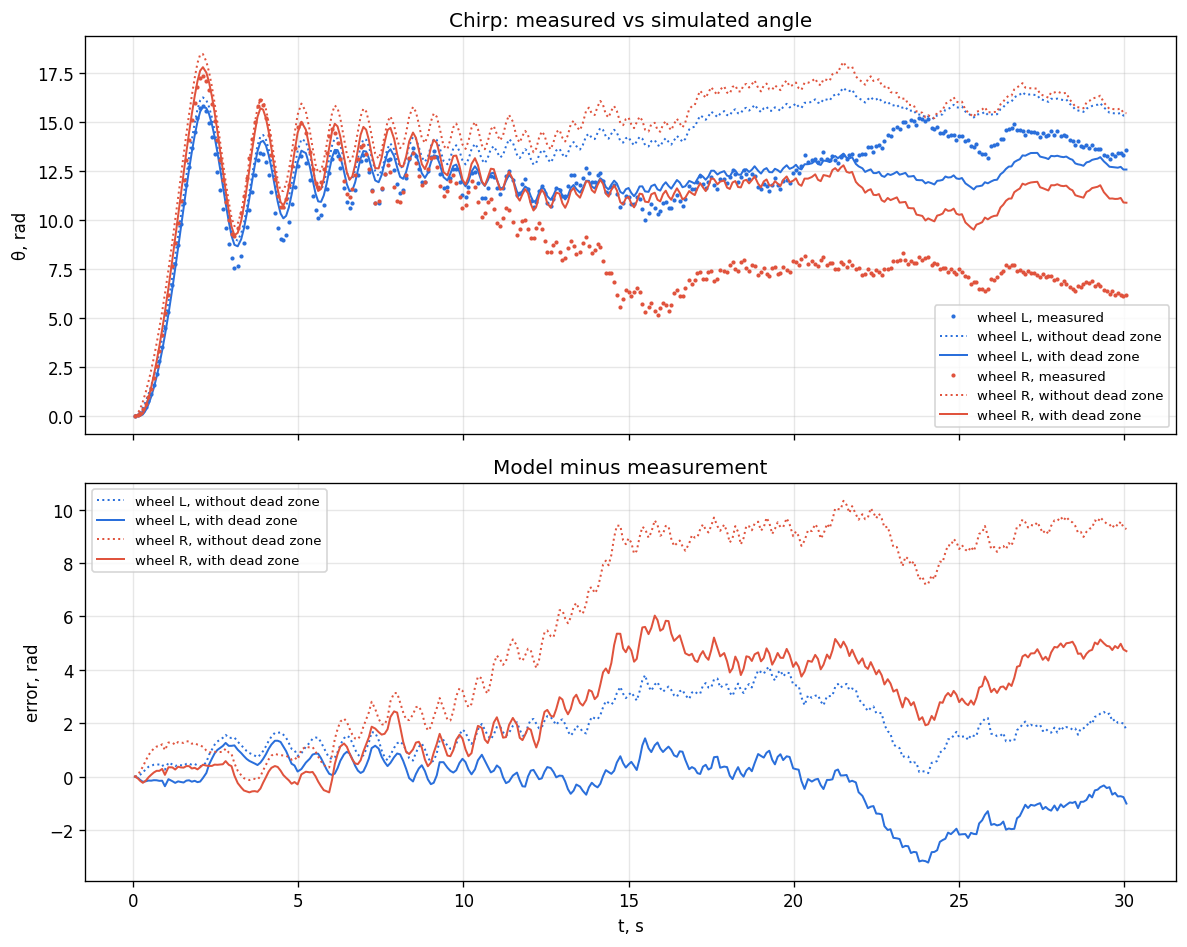

In [23]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), dpi=120, sharex=True)
for wh in ('L', 'R'):
    ax1.plot(t_c, meas[wh], '.', color=colors[wh], ms=3, label=f'wheel {wh}, measured')
    for dz, ls in ((False, ':'), (True, '-')):
        sim = simulate(wh, dz)
        err = sim - meas[wh]
        name = f'wheel {wh}, {"with" if dz else "without"} dead zone'
        print(f'{name}: RMSE {np.sqrt(np.mean(err ** 2)):.2f} rad, fit {fit_percent(meas[wh], sim):.1f} %')
        ax1.plot(t_c, sim, ls, color=colors[wh], lw=1.2, label=name)
        ax2.plot(t_c, err, ls, color=colors[wh], lw=1.2, label=name)

ax1.set_ylabel('θ, rad'); ax1.set_title('Chirp: measured vs simulated angle')
ax2.set_ylabel('error, rad'); ax2.set_xlabel('t, s'); ax2.set_title('Model minus measurement')
for ax in (ax1, ax2):
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('report_figs/chirp_sim.png')
plt.show()

## Chirp simulation
The identified model is simulated with the logged PWM, held constant between samples, for both wheels. *With dead zone:* ω = 0 for |PWM| < 10 %, the fitted line above it. *Without dead zone:* the fitted line all the way down to PWM = 0. Only the dead zone changes between the two.


wheel L, without dead zone: RMSE 2.13 rad, fit 18.1 %
wheel L, with dead zone: RMSE 1.05 rad, fit 59.6 %
wheel R, without dead zone: RMSE 6.97 rad, fit -127.3 %
wheel R, with dead zone: RMSE 3.29 rad, fit -7.3 %


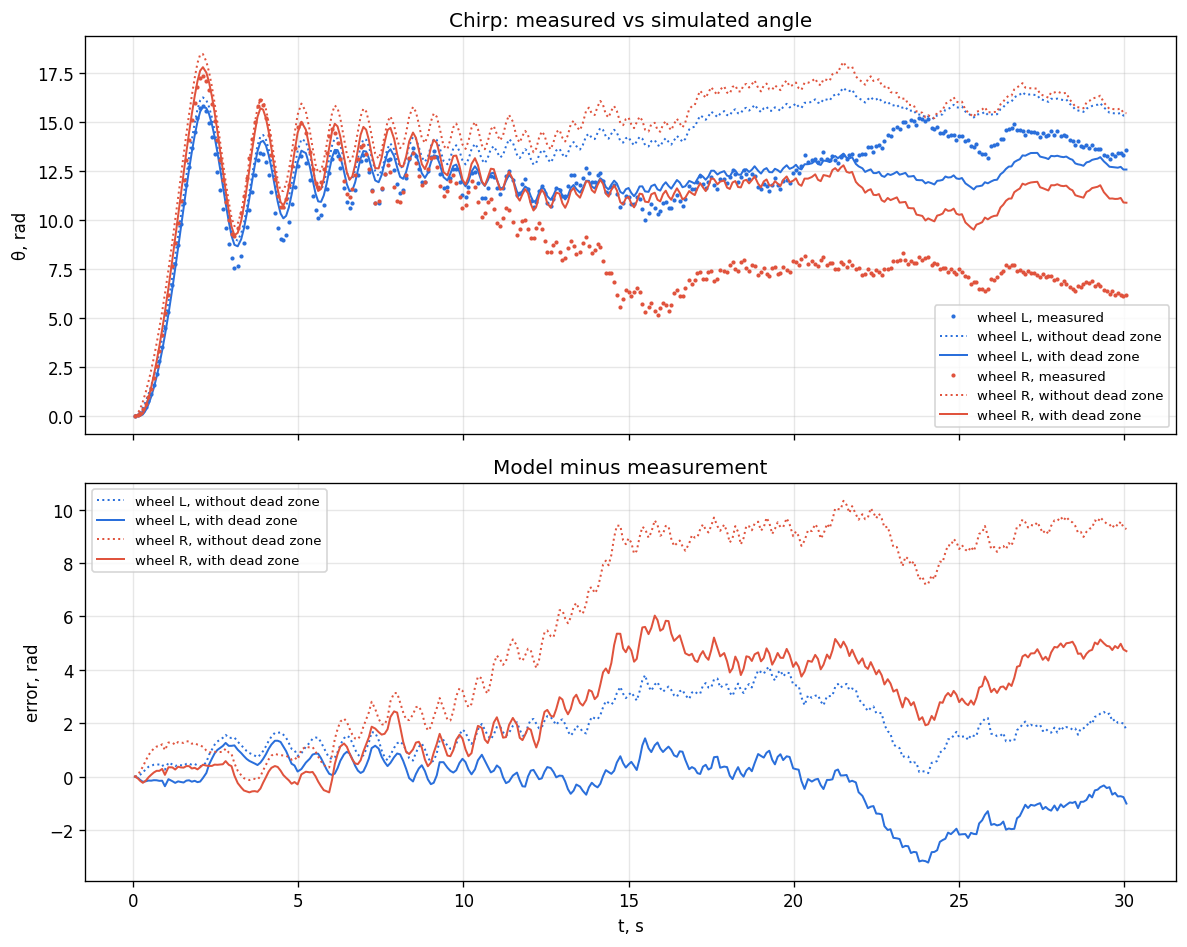

In [ ]:
sig = np.loadtxt('signal_data.txt')                                  # columns: phase, PWM, encL, encR, time_ms, battery
sig = sig[sig[:, 0] == 3]                                            # chirp lines only (phase 2 = zero block)
t_c = sig[:, 4] / 1000                                               # time, s
pwm_c = sig[:, 1]                                                    # PWM actually sent, %
U_c = pwm_c / 100 * sig[:, 5]                                        # applied voltage, V
meas = {'L': np.deg2rad(sig[:, 2]), 'R': np.deg2rad(sig[:, 3])}      # measured angle, rad

def simulate(wh, dead_zone):

    theta, w = np.zeros(len(t_c)), 0.0                               # angle, rad; speed, rad/s
    for k in range(len(t_c) - 1):
        p = params[wh, 'fwd' if pwm_c[k] > 0 else 'rev']
        if pwm_c[k] == 0 or (dead_zone and abs(pwm_c[k]) < p['dz']):
            w_target = 0.0                                           # wheel held by the dead zone
        else:
            w_target = U_c[k] / p['k_e'] + p['b']                     # the fitted line
        dt = t_c[k + 1] - t_c[k]
        e = np.exp(-dt / p['T_m'])
        theta[k + 1] = theta[k] + w_target * dt + (w - w_target) * p['T_m'] * (1 - e)
        w = w_target + (w - w_target) * e
    return theta

def fit_percent(y, y_sim):
    return 100 * (1 - np.linalg.norm(y - y_sim) / np.linalg.norm(y - y.mean()))  # 100 % = perfect fit

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), dpi=120, sharex=True)
for wh in ('L', 'R'):
    ax1.plot(t_c, meas[wh], '.', color=colors[wh], ms=3, label=f'wheel {wh}, measured')
    for dz, ls in ((False, ':'), (True, '-')):
        sim = simulate(wh, dz)
        err = sim - meas[wh]                                         # model minus measurement, rad
        name = f'wheel {wh}, {"with" if dz else "without"} dead zone'
        print(f'{name}: RMSE {np.sqrt(np.mean(err ** 2)):.2f} rad, fit {fit_percent(meas[wh], sim):.1f} %')
        ax1.plot(t_c, sim, ls, color=colors[wh], lw=1.2, label=name)
        ax2.plot(t_c, err, ls, color=colors[wh], lw=1.2, label=name)
ax1.set_ylabel('θ, rad'); ax1.set_title('Chirp: measured vs simulated angle')
ax2.set_ylabel('error, rad'); ax2.set_xlabel('t, s'); ax2.set_title('Model minus measurement')
for ax in (ax1, ax2):
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('report_figs/chirp_sim.png')

## Chirp: amplitude ratio vs frequency
For each sample, the speed and voltage amplitudes are taken over one period of the chirp around it, at the instantaneous frequency $f(t) = f_0 + (f_1 - f_0)\,t/T$. The ratio is compared with the first-order model $1/(k_e\sqrt{1 + (2\pi f T_m)^2})$.


L: measured ratio 1.24 (f < 1 Hz, median), 1/k_e = 0.96, 1/k_e + b/A_U = 1.35 rad/s per V
R: measured ratio 1.35 (f < 1 Hz, median), 1/k_e = 0.85, 1/k_e + b/A_U = 1.44 rad/s per V


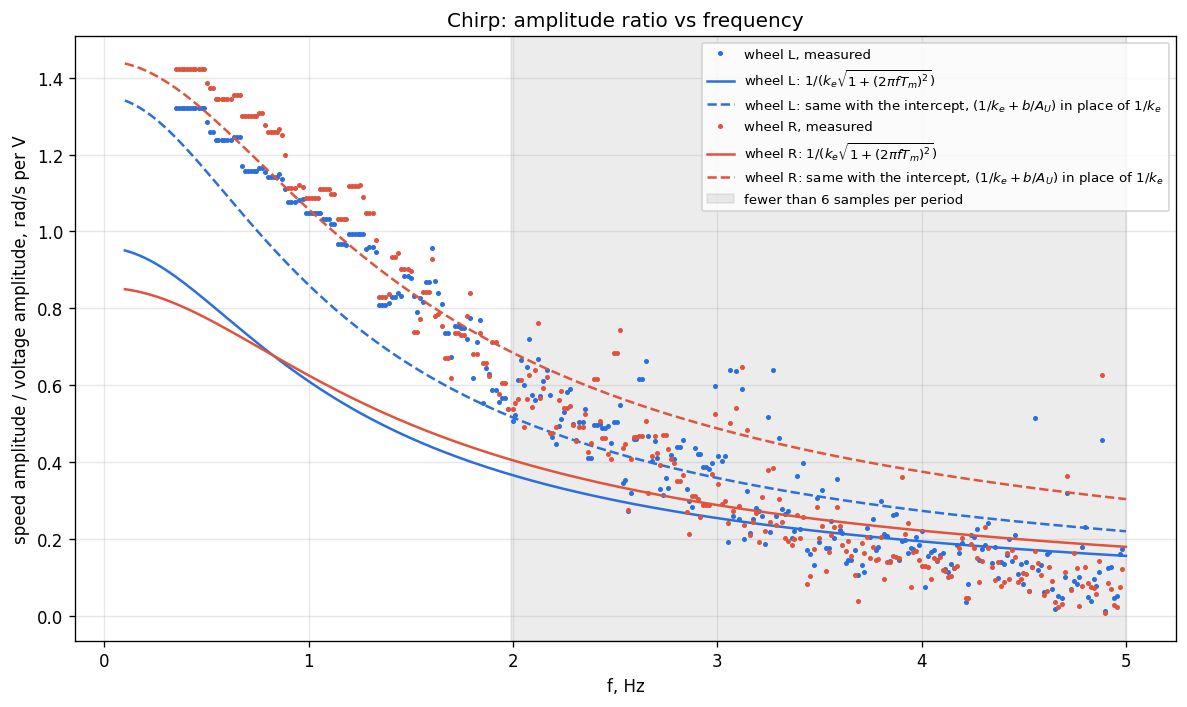

In [24]:
f0, f1, T_chirp = 0.1, 5, 30                                         # chirp settings in motor_signal.qrs
f_c = f0 + (f1 - f0) * t_c / T_chirp                                 # instantaneous frequency, Hz
A_U = np.abs(U_c).max()                                              # input amplitude, V
f_line = np.linspace(f0, f1, 200)

plt.figure(figsize=(10, 6), dpi=120)
for wh in ('L', 'R'):
    w_meas = np.gradient(meas[wh], t_c)                              # measured speed, rad/s
    ratio = np.full(len(t_c), np.nan)
    for k in range(len(t_c)):
        half = 0.5 / f_c[k]                                          # half a period at this frequency, s
        if t_c[k] - half >= t_c[0] and t_c[k] + half <= t_c[-1]:     # a full period fits in the record
            win = np.abs(t_c - t_c[k]) <= half
            ratio[k] = np.ptp(w_meas[win]) / np.ptp(U_c[win])        # speed amplitude / voltage amplitude
    plt.plot(f_c, ratio, '.', color=colors[wh], ms=4, label=f'wheel {wh}, measured')
    k_e = np.mean([params[wh, d]['k_e'] for d in ('fwd', 'rev')])    # averaged over the two directions
    T_m = np.mean([params[wh, d]['T_m'] for d in ('fwd', 'rev')])
    b = np.mean([abs(params[wh, d]['b']) for d in ('fwd', 'rev')])
    lag = np.sqrt(1 + (2 * np.pi * f_line * T_m) ** 2)
    plt.plot(f_line, 1 / (k_e * lag), '-', color=colors[wh], label=f'wheel {wh}: $1/(k_e\\sqrt{{1 + (2\\pi f T_m)^2}})$')
    plt.plot(f_line, (1 / k_e + b / A_U) / lag, '--', color=colors[wh], label=f'wheel {wh}: same with the intercept, $(1/k_e + b/A_U)$ in place of $1/k_e$')
    print(f'{wh}: measured ratio {np.nanmedian(ratio[f_c < 1]):.2f} (f < 1 Hz, median), '
          f'1/k_e = {1 / k_e:.2f}, 1/k_e + b/A_U = {1 / k_e + b / A_U:.2f} rad/s per V')

fs = 1 / np.median(np.diff(t_c))                                     # sampling rate, Hz
plt.axvspan(fs / 6, f1, color='grey', alpha=0.15, label='fewer than 6 samples per period')
plt.xlabel('f, Hz'); plt.ylabel('speed amplitude / voltage amplitude, rad/s per V')
plt.title('Chirp: amplitude ratio vs frequency')
plt.grid(alpha=0.3); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig('report_figs/chirp_ratio.png')
plt.show()

## Artifacts
Zero drift: the 0 % level of both step runs, logged with the motors off. Logging interval: time between consecutive log lines, against the 5 ms target.


run1, 0 % level: 46 samples over 1.9 s, max |θ|: L 0°, R 0°
run2, 0 % level: 37 samples over 1.9 s, max |θ|: L 0°, R 0°
steps, run 1: Δt median 42 ms, 95th percentile 51 ms, max 72 ms
steps, run 2: Δt median 52 ms, 95th percentile 65 ms, max 93 ms
chirp: Δt median 84 ms, 95th percentile 111 ms, max 135 ms


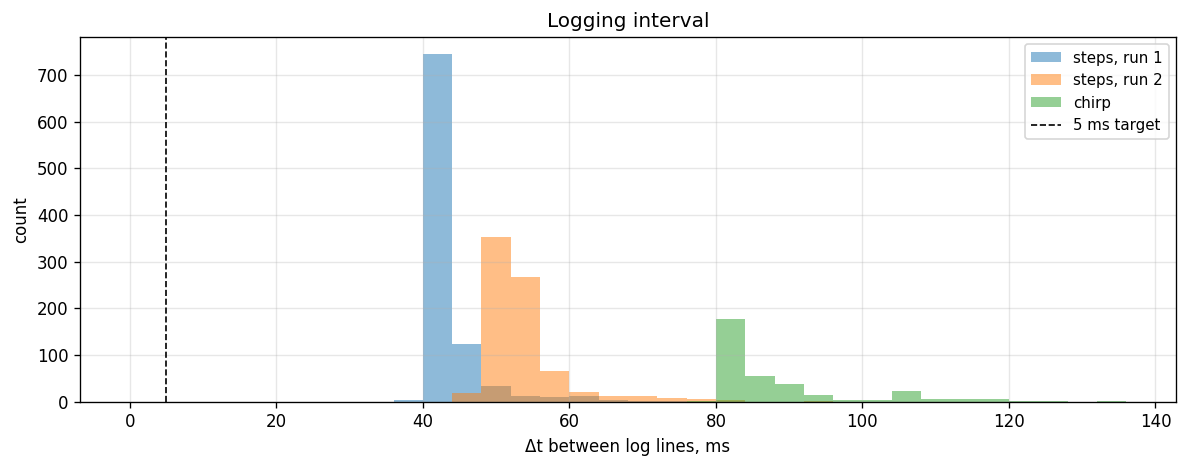

In [25]:
# zero drift: the 0 % level, logged with the motors off
for name in ('run1', 'run2'):
    r0 = next(r for r in all_runs[name] if r['power'] == 0)
    print(f'{name}, 0 % level: {len(r0["time"])} samples over {r0["time"][-1] - r0["time"][0]:.1f} s, '
          f'max |θ|: L {np.degrees(np.abs(r0["L"]).max()):.0f}°, R {np.degrees(np.abs(r0["R"]).max()):.0f}°')

# logging interval jitter: time between consecutive log lines
dts = {'steps, run 1': np.concatenate([np.diff(r['time']) for r in all_runs['run1']]),
       'steps, run 2': np.concatenate([np.diff(r['time']) for r in all_runs['run2']]),
       'chirp':        np.diff(t_c)}
plt.figure(figsize=(10, 4), dpi=120)
for name, dt in dts.items():
    dt_ms = 1000 * dt                                                # ms
    print(f'{name}: Δt median {np.median(dt_ms):.0f} ms, 95th percentile {np.percentile(dt_ms, 95):.0f} ms, '
          f'max {dt_ms.max():.0f} ms')
    plt.hist(dt_ms, bins=np.arange(0, 140, 4), alpha=0.5, label=name)

plt.axvline(5, color='k', ls='--', lw=1, label='5 ms target')
plt.xlabel('Δt between log lines, ms'); plt.ylabel('count'); plt.title('Logging interval')
plt.grid(alpha=0.3); plt.legend(fontsize=9)
plt.tight_layout(); plt.savefig('report_figs/dt_jitter.png')
plt.show()

## Repeatability and load
Run 1 vs. run 2 (both lifted), compared per volt because the battery was ≈ 0.35 V lower in run 2. Lifted (run 2) vs. on the floor at ±50 %, at nearly the same battery voltage.


wheel L: speed per volt, run 2 vs run 1: -3.6 % (mean over |PWM| ≥ 50 %); T_m mean: run 1 0.192 s, run 2 0.198 s
wheel R: speed per volt, run 2 vs run 1: -1.6 % (mean over |PWM| ≥ 50 %); T_m mean: run 1 0.148 s, run 2 0.155 s


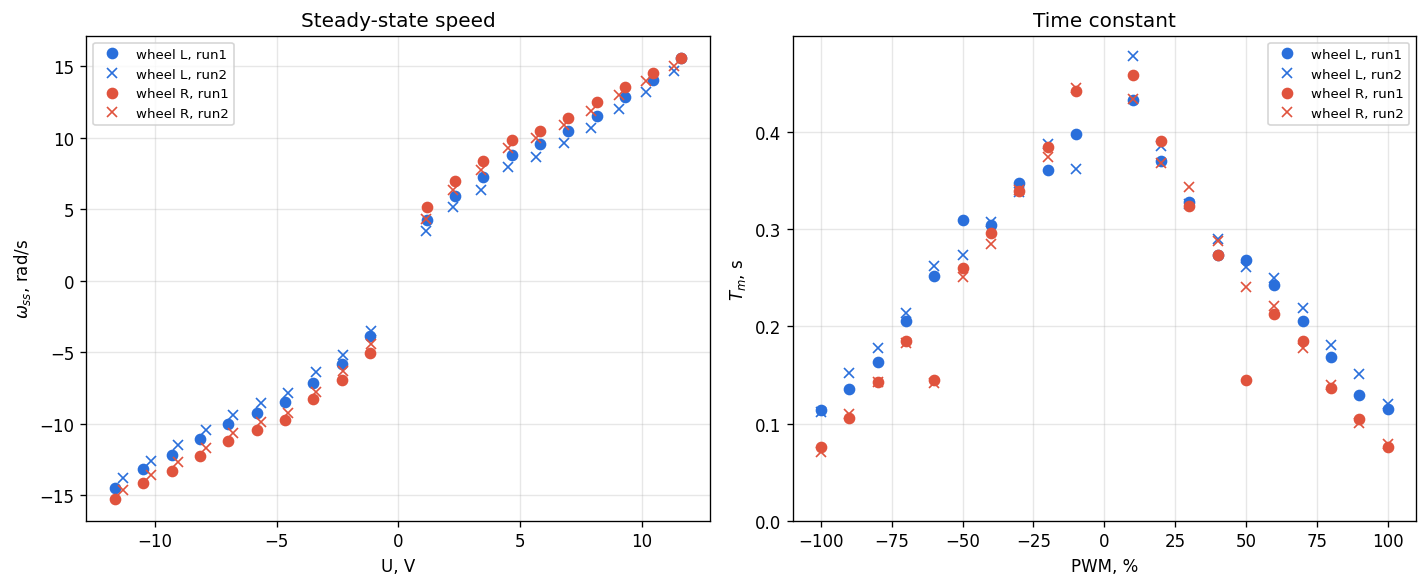

lifted (run 2) → floor:
  PWM  -50, wheel L: ω_ss  -8.56 →  -6.82 rad/s (-20.3 %), T_m 0.273 → 0.393 s
  PWM  -50, wheel R: ω_ss  -9.92 →  -7.32 rad/s (-26.2 %), T_m 0.251 → 0.389 s
  PWM  +50, wheel L: ω_ss   8.67 →   7.33 rad/s (-15.5 %), T_m 0.261 → 0.483 s
  PWM  +50, wheel R: ω_ss   9.96 →   7.51 rad/s (-24.6 %), T_m 0.240 → 0.364 s


In [26]:
def fit_all(runs):
    res = {wh: np.full((len(runs), 2), np.nan) for wh in ('L', 'R')}  # per level: w_ss (rad/s), T_m (s)
    for wh in ('L', 'R'):
        for i, r in enumerate(runs):
            if abs(r[wh][-1]) >= 1:                                  # the wheel moved
                res[wh][i] = fit_run(r['time'], r[wh])[0]
    return res

fits = {name: fit_all(rs) for name, rs in all_runs.items()}
lv = {name: {'pct': np.array([r['power'] for r in rs]),             # PWM of every level, %
             'U':   np.array([r['U'] for r in rs])}                  # voltage of every level, V
      for name, rs in all_runs.items()}
assert np.array_equal(lv['run1']['pct'], lv['run2']['pct'])         # same levels in the same order

# repeatability: run 1 vs run 2, both lifted; compared per volt because the battery differs
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), dpi=120)
hi = np.abs(lv['run1']['pct']) >= 50                                 # the linear part
for wh in ('L', 'R'):
    for name, mk in (('run1', 'o'), ('run2', 'x')):
        ax1.plot(lv[name]['U'], fits[name][wh][:, 0], mk, color=colors[wh], label=f'wheel {wh}, {name}')
        ax2.plot(lv[name]['pct'], fits[name][wh][:, 1], mk, color=colors[wh], label=f'wheel {wh}, {name}')
    g1 = fits['run1'][wh][hi, 0] / lv['run1']['U'][hi]               # speed per volt, run 1
    g2 = fits['run2'][wh][hi, 0] / lv['run2']['U'][hi]               # speed per volt, run 2
    print(f'wheel {wh}: speed per volt, run 2 vs run 1: {100 * np.mean(g2 / g1 - 1):+.1f} % (mean over |PWM| ≥ 50 %); '
          f'T_m mean: run 1 {np.mean(fits["run1"][wh][hi, 1]):.3f} s, run 2 {np.mean(fits["run2"][wh][hi, 1]):.3f} s')

ax1.set_xlabel('U, V'); ax1.set_ylabel('$\\omega_{ss}$, rad/s'); ax1.set_title('Steady-state speed')
ax2.set_xlabel('PWM, %'); ax2.set_ylabel('$T_m$, s'); ax2.set_title('Time constant'); ax2.set_ylim(bottom=0)
for ax in (ax1, ax2):
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('report_figs/repeatability.png')
plt.show()

# load: lifted (run 2) vs on the floor, at nearly the same battery voltage
print('lifted (run 2) → floor:')
for p in (-50, 50):
    i2, i_f = list(lv['run2']['pct']).index(p), list(lv['floor']['pct']).index(p)
    for wh in ('L', 'R'):
        (w2, T2), (wf, Tf) = fits['run2'][wh][i2], fits['floor'][wh][i_f]
        print(f'  PWM {p:+4d}, wheel {wh}: ω_ss {w2:6.2f} → {wf:6.2f} rad/s ({100 * (wf / w2 - 1):+.1f} %), '
              f'T_m {T2:.3f} → {Tf:.3f} s')

### 1. Evaluation of Model Performance
* **Step Response Accuracy:** The single-step responses match the model reasonably well, staying within about a 5% error margin. At the 100% PWM mark, the final simulated angle deviates slightly from the actual measurement by -5.3% on the left wheel and -3.6% on the right wheel.
* **Chirp Signal Tracking:** The complex chirp signal revealed a bigger gap between simulation and reality. The left wheel achieved a moderate 60% fit (falling short of the 85% target benchmark), whereas the right wheel dropped to -7% (worse than a flat-line prediction).
* **Error Accumulation:** Minor velocity discrepancies that are barely noticeable during a quick 2-second step test compound over time during the 30-second chirp test, resulting in a noticeable divergence by the end (e.g., right wheel measured at 6.2 rad vs. 10.8 rad in simulation).

### 2. Directional Asymmetry (Forward vs. Backward)
* **Speed Differences:** Based on the back-EMF constant ($k_e$), forward movement is noticeably faster than reverse on both sides—specifically by 14% on the left motor and 6% on the right motor.
* **Time Constant ($T_m$):** The time constant remains relatively consistent across directions (left motor: 0.188 s forward vs. 0.197 s reverse; right motor: 0.143 s vs. 0.152 s). Given that the standard deviation across testing levels is roughly $\pm0.06$ s, the minor 0.009 s variation is statistically negligible. This directional speed bias is likely driven by asymmetrical gearbox friction or internal driver behavior.

### 3. Key Hardware Artifacts & Impact on Odometry
* **Encoders & Drift:** Zero drift was non-existent; the 0% PWM blocks remained precisely at 0 degrees, confirming the encoders are stable while stationary.
* **Timing Jitter:** Due to file-writing overhead, the data logging intervals were significantly slower than the 5 ms target, recording median loop times of 42 ms, 52 ms, and 84 ms with peak spikes reaching 72–135 ms.
* **Wheel-to-Wheel Discrepancy:** The left wheel runs slower than the right (-8.9% at +50% PWM and -12.4% at -50% PWM), which naturally introduces unintended rotational yaw rates (+11.3 to -15.5 deg/s).
* **Dead Zone & Load:** Static friction causes the motors to stall below 10% PWM. Furthermore, placing the robot on the floor introduces physical load, dropping steady-state speed ($\omega_{ss}$) by 15% to 26% compared to free-spinning lifted tests.
* **Odometry Implication:** While zero drift isn't an issue, the high logging delay matters significantly. Because sampling takes longer, the robot travels along a curved arc between logging updates while its heading shifts, leading to dead-reckoning drift if uncorrected.

### 4. Insights from the Chirp Test
Selecting the chirp signal was particularly revealing because it forces the motor through zero approximately 150 times. Every time the signal flips polarity, the real motor stalls momentarily inside its dead zone. Standard models without a dead-zone condition keep integrating motion through zero, accumulating phantom angular distance. Factoring the dead zone into the simulation fixes this issue and aligns the model closely with physical reality.